In [1]:
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import seaborn as sns
import colorcet as cc
import toolz as tz
import copy

from tqdm.auto import tqdm

from sklearn.metrics import confusion_matrix, balanced_accuracy_score, accuracy_score
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.preprocessing import StandardScaler

plt.rcParams["scatter.edgecolors"] = "none"
plt.rcParams["savefig.bbox"] = 'tight'
plt.rcParams["axes.labelsize"] = 16
np.set_printoptions(legacy="1.21",linewidth=120)

import torch

device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

Using cpu device


# Limpieza de datos

Dejamos sólo las features y los géneros que indica el enunciado.

Simplificamos los nombres de las clases.

Traducimos los géneros a una clase numérica como requiere torch para usar el cross entropy loss.

Dejamos las features `X` y los labels `y` en tensores para usar el DataLoader de torch.

In [2]:
genres = ["dance","jazz","reggae","punk","metal"]
translation = dict(map(reversed,enumerate(genres)))
translation

{'dance': 0, 'jazz': 1, 'reggae': 2, 'punk': 3, 'metal': 4}

In [3]:
%%time 
expr_genre_simplify_names = pl.col("genre").str.replace_many({" and electronica": ""," and blues": "","soul and ": ""})
expr_genre_passlist = pl.col("genre").is_in(genres)
expr_genre_to_int = pl.col("genre").replace_strict(translation)

data = (
  pl.scan_csv("genre_dataset.txt",skip_rows=9,quote_char=None)
  .drop("track_id","title","artist_name")
  .rename({"%genre": "genre"})
  .with_columns(expr_genre_simplify_names)
  .filter(expr_genre_passlist)
  .with_columns(expr_genre_to_int)
  .collect()
)

CPU times: user 328 ms, sys: 153 ms, total: 481 ms
Wall time: 240 ms


In [4]:
data.sample(10)

genre,loudness,tempo,time_signature,key,mode,duration,avg_timbre1,avg_timbre2,avg_timbre3,avg_timbre4,avg_timbre5,avg_timbre6,avg_timbre7,avg_timbre8,avg_timbre9,avg_timbre10,avg_timbre11,avg_timbre12,var_timbre1,var_timbre2,var_timbre3,var_timbre4,var_timbre5,var_timbre6,var_timbre7,var_timbre8,var_timbre9,var_timbre10,var_timbre11,var_timbre12
i64,f64,f64,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
0,-17.141,154.069,4,1,0,206.18404,37.79453,-141.663902,51.939232,7.355512,-1.834715,-3.916208,12.529955,-10.245435,-12.769839,-20.022325,-2.211248,3.944211,13.87604,1199.656652,419.09369,573.934377,207.161928,383.229862,127.042714,214.754596,157.046771,109.571605,112.707301,74.375596
2,-9.151,91.164,4,11,0,194.24608,39.697206,-44.182247,-43.986376,0.697673,-36.999497,12.594833,-22.056847,-4.32877,23.624667,7.573387,-1.776922,12.096928,52.981048,3080.430162,5424.826326,5459.463836,918.264402,2892.294121,762.205768,989.482726,418.790306,556.562406,697.664177,258.54078
0,-7.478,127.989,4,11,0,299.2322,41.566754,25.847463,-31.225496,26.602598,0.590899,-19.769132,11.387978,-2.391059,2.20605,2.63564,7.574939,3.110837,38.925124,4507.507034,2901.707699,1890.08782,1026.369434,1067.432222,900.961991,794.755654,620.220971,356.115355,405.904131,277.343192
1,-17.128,113.648,7,1,1,345.96526,36.778069,74.377844,28.173252,4.944851,17.090617,-10.920365,5.567227,13.230886,-8.189882,11.926197,-6.276372,-0.474287,30.37683,1830.19038,3564.396637,1385.959513,638.696371,804.725996,415.583692,445.59482,371.404392,290.475345,229.811322,494.95975
1,-5.645,89.001,3,10,0,242.46812,49.572601,-11.463993,20.080868,-0.344176,22.458968,-17.435642,12.679685,-0.1017,0.580281,3.898634,-1.835682,3.295001,23.564854,1271.922611,1787.25093,1324.207763,785.366398,543.499084,451.183606,245.508597,304.443937,221.17725,188.934595,251.310934
3,-8.722,125.514,3,0,1,239.04608,45.046337,32.57507,-25.587653,-15.981934,-31.060416,-9.176425,-11.921869,-4.52088,17.117686,2.375568,-1.724055,-2.838588,38.470094,2032.45004,1478.945358,941.097334,742.89477,671.647022,540.871209,518.264644,257.300917,282.370287,228.839251,183.128012
0,-11.462,64.778,5,11,0,151.58812,40.435619,-32.76646,17.780445,27.10582,-31.09498,-12.510876,-11.08094,-2.852483,9.287533,2.393992,7.622351,6.224747,43.145909,4754.336973,2655.700814,1667.419208,1940.752468,1033.405266,1053.550502,517.193897,829.676006,345.147739,532.608116,404.310366
1,-19.707,135.767,7,9,0,410.95791,30.487887,-126.585889,-21.415546,2.540824,-3.28877,-2.669083,-27.455349,-6.431673,-0.207957,3.36953,5.584885,-0.449349,32.89864,2418.208404,1439.97999,1752.148368,646.982291,1091.282208,331.357331,346.152942,410.99987,191.223679,225.399988,205.979088
2,-7.217,165.973,4,7,1,243.3824,46.327208,-3.848347,12.504899,0.401731,-0.514456,-1.945123,-2.741343,-3.280881,2.04165,5.380945,-4.637905,-18.85329,58.303573,1847.437932,1385.331081,1622.089473,943.161005,909.865027,660.336338,538.177709,413.183499,325.715476,347.842,308.267942


In [5]:
X = torch.tensor(data.drop("genre").to_numpy(),dtype=torch.float32)
y = torch.tensor(data["genre"].to_numpy())

Separamos en entrenamiento (60%), validación (20%) y prueba (20%).

Los autores no entienden por qué no existe esta función en las librerías estándar de ML.

In [6]:
def split_thrice(*collections,train_size=0.7,test_size=np.nan,val_size=np.nan,**kwargs):
    """Like sklearn train_test_split but for three categories. kwargs are passed to the sklearn function.
    If two of the sizes are NaN, the other two are assumed equal. If all sizes are None, all are assumed equal.
    The return style is different from sklearn. Tuples with the train, test and validation samples are returned separately."""
    sizes = np.array([train_size,test_size,val_size])
    nan_count = np.isnan(sizes).sum()
    rest = 1-np.nansum(sizes)
    sizes[np.isnan(sizes)] = rest / nan_count
    train_size,test_size,val_size = sizes
    p = train_size
    q = test_size / (1-p)
    first_split = train_test_split(*collections,train_size=p,**kwargs)
    train, other = zip(*tz.partition(2,first_split))
    second_split = train_test_split(*other,train_size=q,**kwargs)
    test, val = zip(*tz.partition(2,second_split))
    return list(train), list(test), list(val)

In [7]:
train, test, val = split_thrice(X,y,train_size=0.7,val_size=0.15,shuffle=True)

Quisiéramos verificar que la distribución de clases es igual en entrenamiento, prueba y validación:

Text(0, 0.5, 'Fracción')

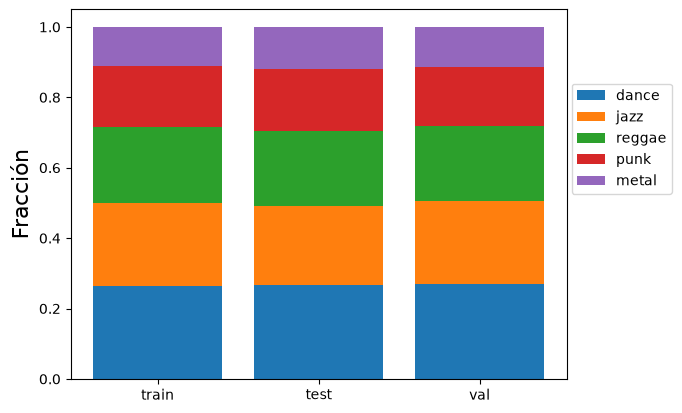

In [8]:
for name,y_ in {"train":train[1],"test":test[1],"val":val[1]}.items():
    xs = np.histogram(y_.cpu(),bins=np.arange(6)-0.5)[0]
    xs = xs/xs.sum()
    bottom = 0
    for i,x_ in enumerate(xs):
        plt.bar(name,x_,bottom=bottom,color=f"C{i}",label=(genres[i] if name=="train" else None))
        bottom += x_
plt.legend(loc=[1.01,0.5])
plt.ylabel("Fracción")

## Escalado

Entrenamos un StandardScaler con los datos de entrenamiento únicamente para evitar data leak.

In [9]:
scaler = StandardScaler().fit(train[0])
for S in [train,test,val]:
    S[0] = torch.tensor(scaler.transform(S[0]),dtype=torch.float32)

## Exporte

Exportamos estos datos divididos y escalados para hacer la búsqueda de grilla de hiperparámetros con los mismos datos (sino estaríamos haciendo data leaking)

In [24]:
for name,struct in {"train":train,"test":test,"val":val}.items():
    np.savez(f"./grid_search/data/{name}.npz",X=struct[0].numpy(),y=struct[1].numpy(),allow_pickle=False)

# Definición del modelo

Creamos una fábrica de perceptrones multicapa para explorar distintas arquitecturas

In [14]:
def make_mlp(input_size:int,output_size:int,hidden_layers=[20,20,20]):
    sizes = [input_size, *hidden_layers, output_size]
    layers = [torch.nn.Linear(a,b,bias=True) for (a,b) in tz.sliding_window(2,sizes)]
    n = len(layers)
    activations = [torch.nn.ReLU() for _ in range(n-1)]
    return torch.nn.Sequential(*tz.interleave([layers,activations]))

# prefiero hacer esto que hacer una subclase
def make_dataloader(X,y,batch_size):
    return torch.utils.data.DataLoader(
        torch.utils.data.TensorDataset(X,y),
        batch_size=batch_size,
        shuffle=True
    )

# Estrategia de entrenamiento

Usaremos Adam para entrenar el modelo, y probamos con los siguientes parámetros que parecen plausibles para una red pequeña.

Revisaremos a detalle este entrenamiento para ver qué se puede hacer masivamente y cóm ose decidirá la condición de parada.

In [212]:
model = make_mlp(
    input_size = X.shape[1],
    output_size = len(y.unique()),
    hidden_layers = [20]*3
)
model.to(device)
loss_fn = torch.nn.CrossEntropyLoss()

learning_rate = 8e-3#7.943e-03#3e-3
batch_size = 400
epochs = 70
L2_lambda = 3e-4


train_loader = make_dataloader(*train,batch_size=batch_size)
test_loader = make_dataloader(*test,batch_size=batch_size)
val_loader = make_dataloader(*val,batch_size=len(val[1]))

optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=L2_lambda, fused=True)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, "min", patience=5, factor=0.5,threshold=0.01)

In [213]:
measures = {
    "train_loss":np.zeros(epochs),
    "val_loss":np.zeros(epochs),
    "lr":np.zeros(epochs),
    "val_acc":np.zeros(epochs)
}

for epoch in tqdm(range(epochs),desc="Epoch"):
    model.train()
    this_epoch_train_losses = []
    for X,y in train_loader:
        pred = model(X)
        loss = loss_fn(pred, y)
        train_loss = loss.item()
        this_epoch_train_losses.append(train_loss)
        loss.backward()
        optimizer.step()
        optimizer.zero_grad(set_to_none=True) # los gradientes son acumulativos por defecto
    model.eval()
    with torch.no_grad(): # por diseño evaluamos todos los datos de validación en un solo batch
        for X,y in val_loader: # aquí sólo hay una iteración
            pred = model(X)
            val_loss = loss_fn(pred, y).item()
            val_acc = balanced_accuracy_score(y.cpu(),pred.argmax(axis=1).cpu())

    scheduler.step(val_loss)
    lr = scheduler.get_last_lr()[0]
    #print(f"{train_loss = :.3f}     {val_loss = :.3f}     {val_acc = :.3f}    {lr = :.0e}")
    measures["train_loss"][epoch] = np.mean(this_epoch_train_losses)
    measures["val_loss"][epoch] = val_loss
    measures["lr"][epoch] = lr
    measures["val_acc"][epoch] = val_acc

Epoch:   0%|          | 0/70 [00:00<?, ?it/s]

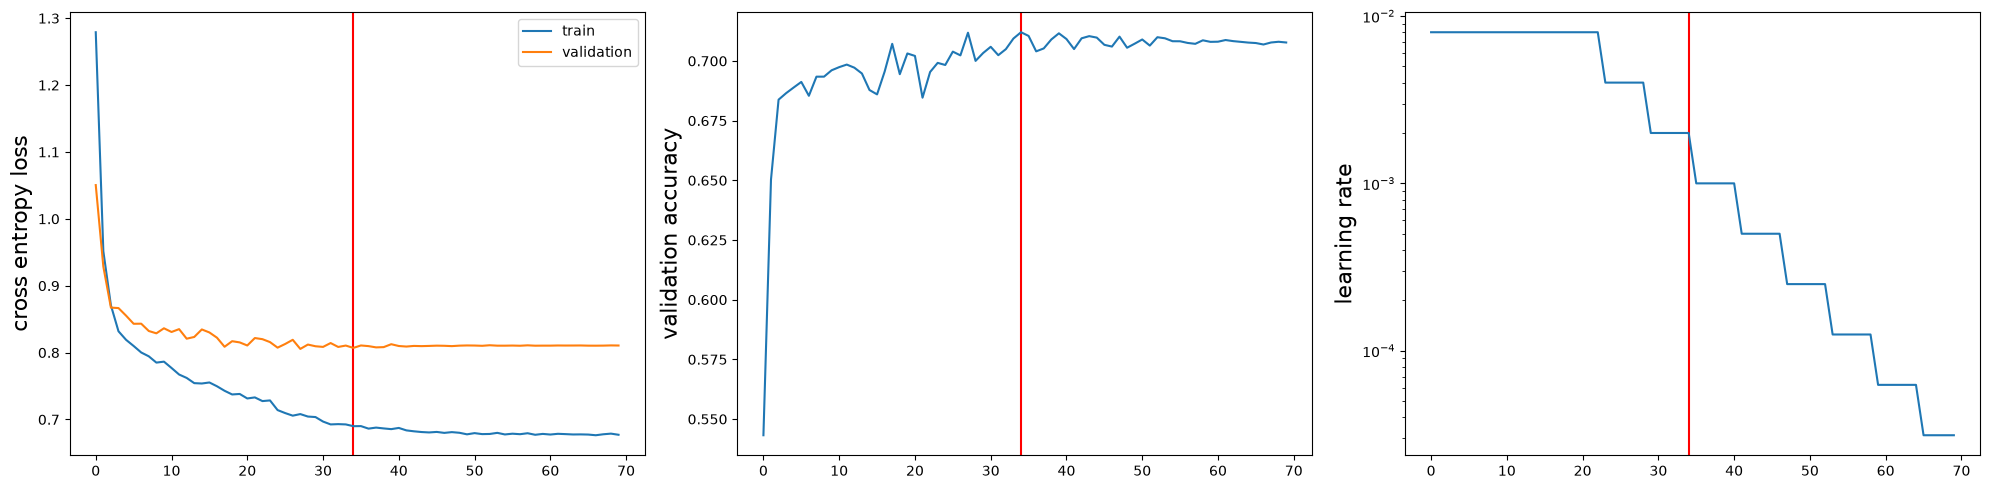

In [214]:
e = measures['val_acc'].argmax()
fig,ax = plt.subplots(1,3,figsize=(20,5))
plt.sca(ax[0]); plt.ylabel("cross entropy loss")
plt.axvline(e,c='r',zorder=-1)
plt.plot(measures["train_loss"],label="train")
plt.plot(measures["val_loss"],label="validation")
plt.legend(loc=0)
plt.sca(ax[1]); plt.ylabel("validation accuracy")
plt.axvline(e,c='r',zorder=-1)
plt.plot(measures['val_acc'])
plt.sca(ax[2]); plt.ylabel("learning rate")
plt.axvline(e,c='r',zorder=-1)
plt.plot(measures["lr"])
plt.yscale("log")
plt.tight_layout()

In [215]:
measures['val_loss'].argmin()

27

In [216]:
measures['val_acc'].max()

0.7120299554053628

In [217]:
measures['val_acc'].argmax()

34

In [218]:
y_pred = model(test[0]).argmax(axis=1).numpy()
y_test = test[1].numpy()

In [219]:
def title(y_true,y_pred,name=""):
    cm = confusion_matrix(y_true,y_pred, normalize="pred")
    tr = np.trace(cm)
    cn = np.linalg.cond(cm)
    bacc = balanced_accuracy_score(y_true,y_pred)
    return f"{name}\ntrace = {tr:.4g}\ncondition number = {cn:.4g}\nbalanced accuracy = {100*bacc:.2f}%"

[Text(0.5, 1.0, '4 layers of 30 neurons\ntrace = 3.624\ncondition number = 1.815\nbalanced accuracy = 71.37%')]

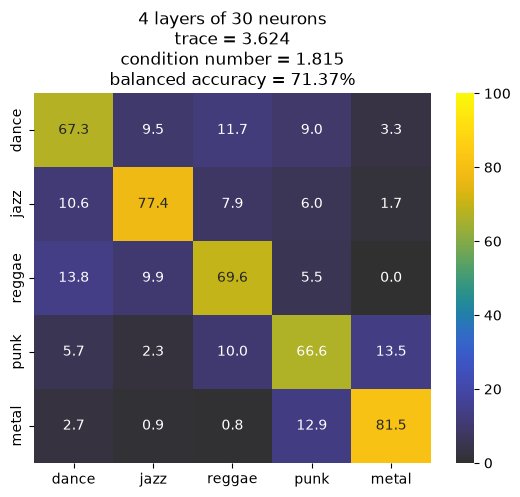

In [220]:
CM = confusion_matrix(y_test,y_pred,normalize="pred")
kwargs = dict(xticklabels=genres,yticklabels=genres,annot=True,fmt='.1f',vmin=0,vmax=100,cmap=cc.cm.gouldian)
report = title(y_test,y_pred,name="4 layers of 30 neurons")
sns.heatmap(100*CM,**kwargs).set(title=report)

# Parada de entrenamiento basada en paciencia

Entrenaremos el modelo hasta un númeor máximo de épocas, llevando cuenta de la mejor accuracy. Dado un número de épcoas de paciencia, si durante el entrenamiento el validation accuracy no mejora respecto al último máximo, pararemos de entrenar y recuperaremos los parámetros del modelo con mejor accuracy.

In [243]:
def train_mlp_classifier(train_Xy,val_Xy,hidden_layers=[20]*3,acc_tol=1e-2,patience=15,
                         learning_rate=1e-3,batch_size=200,max_epochs=100,L2_lambda=1e-4,progress=True):
    n_in = val_Xy[0].shape[1]
    n_out = len(np.unique(train_Xy[1]))
    train_loader = make_dataloader(*train_Xy,batch_size=batch_size)
    val_loader = make_dataloader(*val_Xy,batch_size=len(val[1]))

    model = make_mlp(n_in,n_out,hidden_layers)
    model.to(device)
    loss_fn = torch.nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=L2_lambda, fused=True)
    #scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, "min", patience=3, factor=0.5,threshold=0.01)

    best_acc = -np.inf
    best_state = None
    no_improv = 0

    for epoch in tqdm(range(epochs),desc="Epoch",disable=not progress):
        # Train section
        model.train()
        for X,y in train_loader:
            pred = model(X)
            loss = loss_fn(pred,y)
            loss.backward()
            optimizer.step()
            optimizer.zero_grad(set_to_none=True)
        # validate section
        model.eval()
        with torch.no_grad():
            for X,y in val_loader:
                y_pred = model(X).argmax(axis=1)
                val_acc = balanced_accuracy_score(y.cpu(),y_pred.cpu())
        # check section
        if val_acc > best_acc + acc_tol:
            best_acc = val_acc
            no_improv = 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            no_improv += 1
        if no_improv > patience:
            break
        # learning rate sceduler
        #scheduler.step(val_loss)
    # either way
    print(epoch)
    model.load_state_dict(best_state)
    return model, best_acc

In [244]:
%time train_mlp_classifier(train,val,hidden_layers=[30]*3,batch_size=700,learning_rate=5e-3)

Epoch:   0%|          | 0/70 [00:00<?, ?it/s]

23
CPU times: user 3min 4s, sys: 408 ms, total: 3min 5s
Wall time: 22.1 s


(Sequential(
   (0): Linear(in_features=30, out_features=30, bias=True)
   (1): ReLU()
   (2): Linear(in_features=30, out_features=30, bias=True)
   (3): ReLU()
   (4): Linear(in_features=30, out_features=30, bias=True)
   (5): ReLU()
   (6): Linear(in_features=30, out_features=5, bias=True)
 ),
 0.6932740587808576)

[Text(0.5, 1.0, '3 layers of 30 neurons\ntrace = 3.624\ncondition number = 1.815\nbalanced accuracy = 71.37%')]

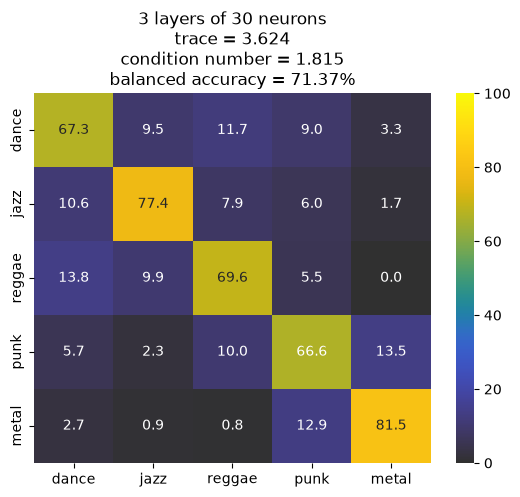

In [246]:
y_pred = model(test[0]).argmax(axis=1).numpy()
y_test = test[1].numpy()

CM = confusion_matrix(y_test,y_pred,normalize="pred")
kwargs = dict(xticklabels=genres,yticklabels=genres,annot=True,fmt='.1f',vmin=0,vmax=100,cmap=cc.cm.gouldian)
report = title(y_test,y_pred,name="3 layers of 30 neurons")
sns.heatmap(100*CM,**kwargs).set(title=report)

# Búsqueda de parámetros

In [26]:
depths = np.unique(np.logspace(0,1.1,7,dtype=int))
depths

array([ 1,  2,  3,  5,  8, 12])

In [27]:
widths = np.unique(np.logspace(0.7,1.55,8,dtype=int))
widths

array([ 5,  6,  8, 11, 15, 20, 26, 35])

In [28]:
learning_rates = np.logspace(-3.5,-2,5)
for lr in learning_rates:
    print(f"{lr:.3e}")

3.162e-04
7.499e-04
1.778e-03
4.217e-03
1.000e-02


In [29]:
batch_sizes = np.logspace(2,2.9,5,dtype=int)
batch_sizes

array([100, 167, 281, 473, 794])

In [30]:
grid = ParameterGrid({
    "depth":depths,
    "width":widths,
    "batch_size":batch_sizes
})

In [32]:
grid[3]

{'width': 11, 'depth': 1, 'batch_size': 100}

In [31]:
len([*grid])

240

In [240]:
240 * 10 / 60 / 30

1.3333333333333333

In [ ]:
learning_rate = 3e-3
batch_size = 120
epochs = 40
L2_lambda = 3e-4